In [ ]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

In [ ]:
import os
import tensorflow as tf
import numpy as np

SEED = 1234
tf.random.set_seed(SEED)

# Get current working directory
cwd = os.getcwd()

In [ ]:
# Run this cell only if you are using Colab with Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

apply_data_augmentation = False

# Create training ImageDataGenerator object
if apply_data_augmentation:
    train_data_gen = ImageDataGenerator(rotation_range=10,
                                        width_shift_range=10,
                                        height_shift_range=10,
                                        zoom_range=0.3,
                                        horizontal_flip=True,
                                        vertical_flip=True,
                                        fill_mode='constant',
                                        cval=0,
                                        rescale=1./255)
else:
    train_data_gen = ImageDataGenerator(rescale=1./255)

# Create validation and test ImageDataGenerator objects
valid_data_gen = ImageDataGenerator(rescale=1./255)
test_data_gen = ImageDataGenerator(rescale=1./255)

In [ ]:
# Run this cell only if you are using Colab with Drive
!unzip '/content/drive/My Drive/Keras3/CNN/MaskDetection/MaskDataset.zip'

Streaming output truncated to the last 5000 lines.
  inflating: MaskDataset/Train/WithoutMask/1858.png  
  inflating: MaskDataset/Train/WithoutMask/1859.png  
  inflating: MaskDataset/Train/WithoutMask/1860.png  
  inflating: MaskDataset/Train/WithoutMask/1861.png  
  inflating: MaskDataset/Train/WithoutMask/1862.png  
  inflating: MaskDataset/Train/WithoutMask/1863.png  
  inflating: MaskDataset/Train/WithoutMask/1864.png  
  inflating: MaskDataset/Train/WithoutMask/1865.png  
  inflating: MaskDataset/Train/WithoutMask/1866.png  
  inflating: MaskDataset/Train/WithoutMask/1867.png  
  inflating: MaskDataset/Train/WithoutMask/1868.png  
  inflating: MaskDataset/Train/WithoutMask/1869.png  
  inflating: MaskDataset/Train/WithoutMask/1870.png  
  inflating: MaskDataset/Train/WithoutMask/1871.png  
  inflating: MaskDataset/Train/WithoutMask/1872.png  
  inflating: MaskDataset/Train/WithoutMask/1873.png  
  inflating: MaskDataset/Train/WithoutMask/1874.png  
  inflating: MaskDataset/Train/

In [ ]:
!ls /content/MaskDataset/

Test  Train  Validation


In [ ]:
!ls /content/MaskDataset/Train

WithMask  WithoutMask


In [ ]:
# Create generators to read images from dataset directory
# -------------------------------------------------------
dataset_dir = os.path.join(cwd, 'MaskDataset')
dataset_dir

# Batch size
bs = 32

# img shape
img_h = 256
img_w = 256

num_classes=2

decide_class_indices = True
if decide_class_indices:
    classes = ['WithoutMask',       # 0
               'WithMask',          # 1
               ]
else:
    classes=None

# Training
training_dir = os.path.join(dataset_dir, 'Train')
train_gen = train_data_gen.flow_from_directory(training_dir,
                                               batch_size=bs,
                                               target_size=[img_h, img_w],
                                               classes=classes,
                                               class_mode='categorical',
                                               shuffle=True,
                                               seed=SEED)  # targets are directly converted into one-hot vectors

# Validation
validation_dir = os.path.join(dataset_dir, 'Validation')
valid_gen = valid_data_gen.flow_from_directory(validation_dir,
                                               batch_size=bs,
                                               target_size=[img_h, img_w],
                                               classes=classes,
                                               class_mode='categorical',
                                               shuffle=False,
                                               seed=SEED)

# Test
test_dir = os.path.join(dataset_dir, 'Test')
test_gen = test_data_gen.flow_from_directory(test_dir,
                                             batch_size=bs,
                                             target_size=[img_h, img_w],
                                             classes=classes,
                                             class_mode='categorical',
                                             shuffle=False,
                                             seed=SEED)

'/content/MaskDataset'

Found 10000 images belonging to 2 classes.
Found 800 images belonging to 2 classes.
Found 992 images belonging to 2 classes.


In [ ]:
# Check how keras assigned the labels
train_gen.class_indices

{'WithoutMask': 0, 'WithMask': 1}

In [ ]:
# Create Dataset objects
# ----------------------

# Training
train_dataset = tf.data.Dataset.from_generator(lambda: train_gen,
                                               output_types=(tf.float32, tf.float32),
                                               output_shapes=([None, img_h, img_w, 3], [None, num_classes]))

train_dataset = train_dataset.repeat()

# Validation
# ----------
valid_dataset = tf.data.Dataset.from_generator(lambda: valid_gen,
                                               output_types=(tf.float32, tf.float32),
                                               output_shapes=([None, img_h, img_w, 3], [None, num_classes]))

# Repeat
valid_dataset = valid_dataset.repeat()

# Test
# ----
test_dataset = tf.data.Dataset.from_generator(lambda: test_gen,
                                              output_types=(tf.float32, tf.float32),
                                              output_shapes=([None, img_h, img_w, 3], [None, num_classes]))

# Repeat
test_dataset = valid_dataset.repeat()

In [ ]:
# Architecture: Features extraction -> Classifier

start_f = 8
depth = 5

model = tf.keras.Sequential()

encoder = tf.keras.Sequential()

# Features extraction
for i in range(depth):

    if i == 0:
        input_shape = [img_h, img_w, 3]
    else:
        input_shape=[None]

    # Conv block: Conv2D -> Activation -> Pooling
    encoder.add(tf.keras.layers.Conv2D(filters=start_f,
                                     kernel_size=(3, 3),
                                     strides=(1, 1),
                                     padding='same',
                                     input_shape=input_shape))
    encoder.add(tf.keras.layers.ReLU())

    if i < depth -1:
      encoder.add(tf.keras.layers.MaxPool2D(pool_size=(2, 2)))

    start_f *= 2

model.add(encoder)

# GAP
model.add(tf.keras.layers.GlobalAveragePooling2D())

# Classifier
model.add(tf.keras.layers.Dense(units=num_classes, activation='softmax'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# Visualize created model as a table
encoder.summary()
model.summary()

# Visualize initialized weights
# model.weights

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 256, 256, 8)    │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 256, 256, 8)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 128, 128, 8)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 16)   │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 128, 128, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 16, 16, 128)    │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 98,384 (384.31 KB)

 Trainable params: 98,384 (384.31 KB)

 Non-trainable params: 0 (0.00 B)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 16, 16, 128)    │        98,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 98,642 (385.32 KB)

 Trainable params: 98,642 (385.32 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.layers[-1].weights[0].shape

TensorShape([128, 2])

In [ ]:
# Optimization params
# -------------------

# Loss
loss = tf.keras.losses.CategoricalCrossentropy()

# learning rate
lr = 1e-3
optimizer = tf.keras.optimizers.Adam(learning_rate=lr)
# -------------------

# Validation metrics
# ------------------

metrics = ['accuracy']
# ------------------

# Compile Model
model.compile(optimizer=optimizer, loss=loss, metrics=metrics)

In [ ]:
%load_ext tensorboard
%tensorboard --logdir /content/drive/My\ Drive/Keras3/CNN/MaskDetection/segmentation_experiments_GAP/#

In [ ]:
import os
from datetime import datetime


cwd = os.getcwd()

exps_dir = os.path.join('/content/drive/My Drive/Keras3/CNN', 'MaskDetection')
if not os.path.exists(exps_dir):
    os.makedirs(exps_dir)

now = datetime.now().strftime('%b%d_%H-%M-%S')

model_name = 'CNN_GAP'

exp_dir = os.path.join(exps_dir, model_name + '_' + str(now))
if not os.path.exists(exp_dir):
    os.makedirs(exp_dir)

callbacks = []

# Model checkpoint
# ----------------
ckpt_dir = os.path.join(exp_dir, 'ckpts')
if not os.path.exists(ckpt_dir):
    os.makedirs(ckpt_dir)

ckpt_callback = tf.keras.callbacks.ModelCheckpoint(filepath=os.path.join(ckpt_dir, 'cp_{epoch:02d}.weights.h5'),
                                                   save_weights_only=True)  # False to save the model directly
callbacks.append(ckpt_callback)

# Visualize Learning on Tensorboard
# ---------------------------------
tb_dir = os.path.join(exp_dir, 'tb_logs')
if not os.path.exists(tb_dir):
    os.makedirs(tb_dir)

# By default shows losses and metrics for both training and validation
tb_callback = tf.keras.callbacks.TensorBoard(log_dir=tb_dir,
                                             profile_batch=0,
                                             histogram_freq=1)  # if 1 shows weights histograms
callbacks.append(tb_callback)

# Early Stopping
# --------------
early_stop = True
if early_stop:
    es_callback = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10)
    callbacks.append(es_callback)

In [ ]:
model.fit(x=train_dataset,
          epochs=7,  #### set repeat in training dataset
          steps_per_epoch=len(train_gen),
          validation_data=valid_dataset,
          validation_steps=len(valid_gen),
          callbacks=callbacks)

# How to visualize Tensorboard

# 1. tensorboard --logdir EXPERIMENTS_DIR --port PORT     <- from terminal
# 2. localhost:PORT   <- in your browser

Epoch 1/7
313/313 ━━━━━━━━━━━━━━━━━━━━ 28s 89ms/step - accuracy: 0.9924 - loss: 0.0191 - val_accuracy: 0.9937 - val_loss: 0.0266
Epoch 2/7
313/313 ━━━━━━━━━━━━━━━━━━━━ 28s 90ms/step - accuracy: 0.9925 - loss: 0.0191 - val_accuracy: 0.9812 - val_loss: 0.0451
Epoch 3/7
313/313 ━━━━━━━━━━━━━━━━━━━━ 28s 90ms/step - accuracy: 0.9955 - loss: 0.0129 - val_accuracy: 0.9900 - val_loss: 0.0301
Epoch 4/7
313/313 ━━━━━━━━━━━━━━━━━━━━ 41s 130ms/step - accuracy: 0.9955 - loss: 0.0118 - val_accuracy: 0.9725 - val_loss: 0.0918
Epoch 5/7
313/313 ━━━━━━━━━━━━━━━━━━━━ 28s 88ms/step - accuracy: 0.9888 - loss: 0.0284 - val_accuracy: 0.9962 - val_loss: 0.0227
Epoch 6/7
313/313 ━━━━━━━━━━━━━━━━━━━━ 27s 87ms/step - accuracy: 0.9958 - loss: 0.0107 - val_accuracy: 0.9887 - val_loss: 0.0307
Epoch 7/7
313/313 ━━━━━━━━━━━━━━━━━━━━ 27s 87ms/step - accuracy: 0.9953 - loss: 0.0173 - val_accuracy: 0.9937 - val_loss: 0.0185


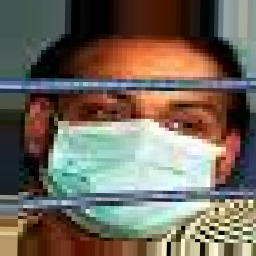

In [ ]:
# Let's visualize the activations of our network
from PIL import Image

test_iter = iter(test_dataset)

# Get a test image with a mask
test_img, target = next(test_iter)
test_img = test_img[0]

# Visualize the image
Image.fromarray(np.uint8(np.array(test_img)*255.))

In [ ]:
model.inputs

[<KerasTensor shape=(None, 256, 256, 3), dtype=float32, sparse=False, ragged=False, name=keras_tensor_106>]

In [ ]:
np.argmax(target, 1)

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [ ]:
# Build the model explicitly before accessing input/output tensors

out_model = tf.keras.Model(inputs=model.inputs, outputs=[model.outputs, model.layers[0].output])

In [ ]:
resize_feature = tf.keras.layers.Resizing(
    256, 256, interpolation="bilinear")

In [ ]:
softmax_out, last_enc_feature = out_model(tf.expand_dims(test_img, 0))

pred = tf.argmax(softmax_out, 1)

resized_feature = resize_feature(last_enc_feature)

In [ ]:
# Get the weights in input to the output neuron corresponding to the 'with_mask' class
mask_weights = model.layers[-1].weights[0][:, 1]

resized_feature = tf.reshape(resized_feature, shape=[256*256, resized_feature.shape[-1]])
cam = tf.linalg.matmul(resized_feature, tf.expand_dims(mask_weights, -1))
cam = tf.reshape(cam, shape=[256, 256])

Class Activation Mapping

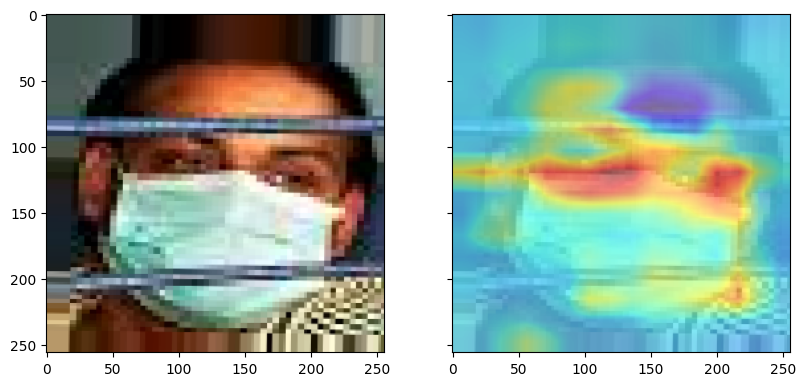

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(nrows=1, ncols=2, sharey=True, sharex=True, figsize=plt.figaspect(0.5))
ax[0].imshow(test_img)
ax[1].imshow(test_img, alpha=0.5)
ax[1].imshow(cam, cmap='jet', alpha=0.5)
plt.show()